# Germany Electricity Generation Analysis

An exploratory data analysis of Germany's electricity generation using Python. The project examines generation by energy source, renewable and non-renewable shares, monthly trends, and seasonal patterns.

**Period covered:** 6 November 2025 – 7 November 2026  
**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn

> This notebook documents the Python analysis. The cleaned dataset is exported for further exploration and dashboard development in Power BI.

## 1. Project Objectives

- Inspect and understand the electricity-generation dataset.
- Prepare date and generation fields for analysis.
- Identify missing or unusable observations.
- Compare electricity generation across energy sources.
- Calculate renewable and non-renewable generation shares.
- Explore monthly generation trends and energy-mix patterns.
- Export a cleaned dataset for Power BI.

## 2. Load the Dataset and Inspect Its Structure

Load the raw CSV file and review its dimensions, column names, and data types before making changes.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "germany-electricity-generation.csv",
    sep=";",
    thousands=","
)

df.head()

,Start date,End date,Biomass [MWh] Calculated resolutions,Hydropower [MWh] Calculated resolutions,Wind offshore [MWh] Calculated resolutions,Wind onshore [MWh] Calculated resolutions,Photovoltaics [MWh] Calculated resolutions,Other renewable [MWh] Calculated resolutions,Nuclear [MWh] Calculated resolutions,Lignite [MWh] Calculated resolutions,Hard coal [MWh] Calculated resolutions,Fossil gas [MWh] Calculated resolutions,Hydro pumped storage [MWh] Calculated resolutions,Other conventional [MWh] Calculated resolutions
0,"Nov 6, 2025 9:00 PM","Nov 6, 2025 10:00 PM","4,375.40","1,517.30","2,675.56","12,988.19",7.32,113.09,-,"10,863.19","5,672.11","11,649.26",142.57,"1,989.91"
1,"Nov 6, 2025 10:00 PM","Nov 6, 2025 11:00 PM","4,245.53","1,519.93","2,089.78","12,229.86",7.06,114.07,-,"10,812.25","5,400.33","11,221.63",73.78,"2,017.44"
2,"Nov 6, 2025 11:00 PM","Nov 7, 2025 12:00 AM","4,115.70","1,551.25","1,477.24","11,651.45",9.51,114.04,-,"10,468.12","4,983.15","10,645.26",2.65,"2,057.56"
3,"Nov 7, 2025 12:00 AM","Nov 7, 2025 1:00 AM","4,003.92","1,548.23","1,070.72","10,864.32",6.63,114.45,-,"10,432.10","4,558.19","10,727.61",2.82,"1,712.64"
4,"Nov 7, 2025 1:00 AM","Nov 7, 2025 2:00 AM","3,967.89","1,543.24",932.68,"10,211.94",8.46,115.79,-,"10,146.41","4,277.29","10,600.36",2.85,"1,740.71"


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (8784, 14)

Column names:
['Start date', 'End date', 'Biomass [MWh] Calculated resolutions', 'Hydropower [MWh] Calculated resolutions', 'Wind offshore [MWh] Calculated resolutions', 'Wind onshore [MWh] Calculated resolutions', 'Photovoltaics [MWh] Calculated resolutions', 'Other renewable [MWh] Calculated resolutions', 'Nuclear [MWh] Calculated resolutions', 'Lignite [MWh] Calculated resolutions', 'Hard coal [MWh] Calculated resolutions', 'Fossil gas [MWh] Calculated resolutions', 'Hydro pumped storage [MWh] Calculated resolutions', 'Other conventional [MWh] Calculated resolutions']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 14 columns):
 #   Column                                             Non-Null Count  Dtype
---  ------                                             --------------  -----
 0   Start date                                         8784 non-null   str  
 1   End date                              

## 3. Data Preparation and Quality Checks

Convert date fields to datetime, normalize generation values to numeric types, and inspect missing values. The notebook then removes the fully empty Nuclear field and the final incomplete observations identified during the quality checks.

In [5]:
# Tarix sütunlarını datetime formatına çevirək
date_columns = ["Start date", "End date"]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format="%b %d, %Y %I:%M %p"
    )

# Enerji sütunlarını rəqəmsal formata çevirək
energy_columns = df.columns.drop(date_columns)

for col in energy_columns:
    df[col] = pd.to_numeric(
        df[col].str.replace(",", "", regex=False).replace("-", np.nan),
        errors="coerce"
    )

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 14 columns):
 #   Column                                             Non-Null Count  Dtype         
---  ------                                             --------------  -----         
 0   Start date                                         8784 non-null   datetime64[us]
 1   End date                                           8784 non-null   datetime64[us]
 2   Biomass [MWh] Calculated resolutions               8781 non-null   float64       
 3   Hydropower [MWh] Calculated resolutions            8781 non-null   float64       
 4   Wind offshore [MWh] Calculated resolutions         8781 non-null   float64       
 5   Wind onshore [MWh] Calculated resolutions          8781 non-null   float64       
 6   Photovoltaics [MWh] Calculated resolutions         8781 non-null   float64       
 7   Other renewable [MWh] Calculated resolutions       8781 non-null   float64       
 8   Nuclear [MWh] Calculated reso

In [7]:
# Hər sütundakı boş dəyərlərin sayı
print(df.isna().sum())

# Boş enerji göstəricisi olan tarixlər
missing_rows = df[df[energy_columns].isna().any(axis=1)]

missing_rows[["Start date", "End date"]]

Start date                                              0
End date                                                0
Biomass [MWh] Calculated resolutions                    3
Hydropower [MWh] Calculated resolutions                 3
Wind offshore [MWh] Calculated resolutions              3
Wind onshore [MWh] Calculated resolutions               3
Photovoltaics [MWh] Calculated resolutions              3
Other renewable [MWh] Calculated resolutions            3
Nuclear [MWh] Calculated resolutions                 8784
Lignite [MWh] Calculated resolutions                    3
Hard coal [MWh] Calculated resolutions                  3
Fossil gas [MWh] Calculated resolutions                 3
Hydro pumped storage [MWh] Calculated resolutions       3
Other conventional [MWh] Calculated resolutions         3
dtype: int64


,Start date,End date
0,2025-11-06 21:00:00,2025-11-06 22:00:00
1,2025-11-06 22:00:00,2025-11-06 23:00:00
2,2025-11-06 23:00:00,2025-11-07 00:00:00
3,2025-11-07 00:00:00,2025-11-07 01:00:00
4,2025-11-07 01:00:00,2025-11-07 02:00:00
...,...,...
8779,2026-11-07 16:00:00,2026-11-07 17:00:00
8780,2026-11-07 17:00:00,2026-11-07 18:00:00
8781,2026-11-07 18:00:00,2026-11-07 19:00:00
8782,2026-11-07 19:00:00,2026-11-07 20:00:00


In [8]:
# Nuclear sütununu analizdən kənarlaşdırırıq
valid_energy_columns = energy_columns.drop(
    "Nuclear [MWh] Calculated resolutions"
)

# Digər enerji sütunlarında boş dəyəri olan sətirlər
missing_rows = df[
    df[valid_energy_columns].isna().any(axis=1)
]

missing_rows[["Start date", "End date"] + list(valid_energy_columns)]

,Start date,End date,Biomass [MWh] Calculated resolutions,Hydropower [MWh] Calculated resolutions,Wind offshore [MWh] Calculated resolutions,Wind onshore [MWh] Calculated resolutions,Photovoltaics [MWh] Calculated resolutions,Other renewable [MWh] Calculated resolutions,Lignite [MWh] Calculated resolutions,Hard coal [MWh] Calculated resolutions,Fossil gas [MWh] Calculated resolutions,Hydro pumped storage [MWh] Calculated resolutions,Other conventional [MWh] Calculated resolutions
8781,2026-11-07 18:00:00,2026-11-07 19:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8782,2026-11-07 19:00:00,2026-11-07 20:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8783,2026-11-07 20:00:00,2026-11-07 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Tamamilə boş olan Nuclear sütununu silək
df = df.drop(columns=["Nuclear [MWh] Calculated resolutions"])

# Son 3 boş sətri silək
df = df.dropna()

# Dataset-in yeni ölçüsünü yoxlayaq
print("Dataset shape:", df.shape)

# Boş dəyərləri yenidən yoxlayaq
print(df.isna().sum().sum())

Dataset shape: (8781, 13)
0


## 4. Generation by Energy Source

Aggregate electricity generation by source, sort the results, and calculate each source's contribution to the total. The chart provides a comparison of the relative scale of the different generation sources.

In [10]:
# Tarix sütunlarını analizdən kənarlaşdırırıq
energy_columns = df.columns.drop(["Start date", "End date"])

# Hər enerji mənbəyinin ümumi istehsalını hesablayırıq
energy_analysis = (
    df[energy_columns]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

energy_analysis.columns = ["energy_source", "total_generation_mwh"]

energy_analysis

,energy_source,total_generation_mwh
0,Wind onshore [MWh] Calculated resolutions,1.111776e+08
1,Photovoltaics [MWh] Calculated resolutions,8.509763e+07
2,Lignite [MWh] Calculated resolutions,6.841173e+07
3,Fossil gas [MWh] Calculated resolutions,6.261164e+07
4,Biomass [MWh] Calculated resolutions,3.529963e+07
5,Hard coal [MWh] Calculated resolutions,3.109140e+07
6,Wind offshore [MWh] Calculated resolutions,2.955797e+07
7,Other conventional [MWh] Calculated resolutions,1.531508e+07
8,Hydropower [MWh] Calculated resolutions,1.219261e+07
9,Hydro pumped storage [MWh] Calculated resolutions,9.912980e+06


In [11]:
# Bütün enerji mənbələrinin ümumi istehsalı
total_generation = energy_analysis["total_generation_mwh"].sum()

# Hər mənbənin ümumi istehsaldakı faiz payı
energy_analysis["share_percent"] = (
    energy_analysis["total_generation_mwh"] / total_generation * 100
)

# Faizləri 2 rəqəmə yuvarlaqlaşdırırıq
energy_analysis["share_percent"] = energy_analysis["share_percent"].round(2)

energy_analysis

,energy_source,total_generation_mwh,share_percent
0,Wind onshore [MWh] Calculated resolutions,1.111776e+08,24.09
1,Photovoltaics [MWh] Calculated resolutions,8.509763e+07,18.44
2,Lignite [MWh] Calculated resolutions,6.841173e+07,14.82
3,Fossil gas [MWh] Calculated resolutions,6.261164e+07,13.57
4,Biomass [MWh] Calculated resolutions,3.529963e+07,7.65
5,Hard coal [MWh] Calculated resolutions,3.109140e+07,6.74
6,Wind offshore [MWh] Calculated resolutions,2.955797e+07,6.40
7,Other conventional [MWh] Calculated resolutions,1.531508e+07,3.32
8,Hydropower [MWh] Calculated resolutions,1.219261e+07,2.64
9,Hydro pumped storage [MWh] Calculated resolutions,9.912980e+06,2.15


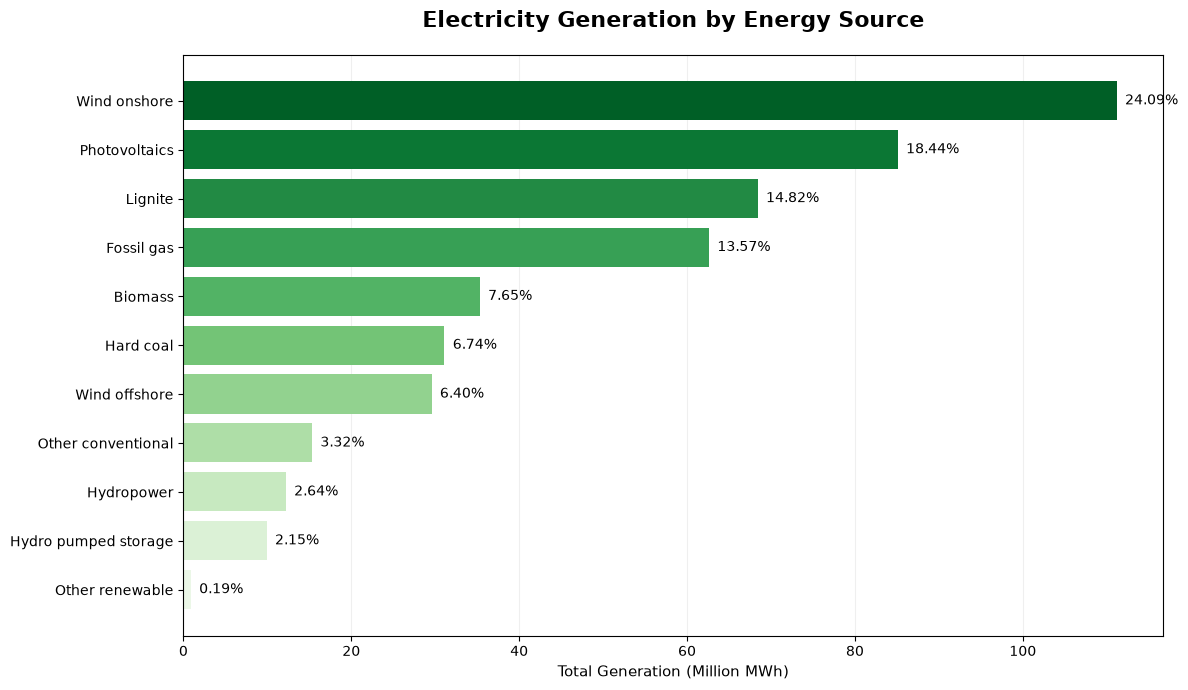

In [12]:
# Enerji mənbələrinin adlarını qısaldaq
chart_data = energy_analysis.copy()

chart_data["energy_source"] = (
    chart_data["energy_source"]
    .str.replace(" [MWh] Calculated resolutions", "", regex=False)
)

# Qrafik ölçüsü
plt.figure(figsize=(12, 7))

# Yaşıl rəng palitrası
colors = sns.color_palette(
    "Greens",
    n_colors=len(chart_data)
)[::-1]

# Horizontal bar chart
bars = plt.barh(
    chart_data["energy_source"],
    chart_data["total_generation_mwh"] / 1_000_000,
    color=colors
)

# Ən böyük göstəricini yuxarıda göstərək
plt.gca().invert_yaxis()

# Başlıq və oxlar
plt.title(
    "Electricity Generation by Energy Source",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Total Generation (Million MWh)", fontsize=11)
plt.ylabel("")

# Faiz göstəricilərini barların yanında yazaq
for bar, percentage in zip(
    bars,
    chart_data["share_percent"]
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.2f}%",
        va="center",
        fontsize=10
    )

plt.grid(axis="x", alpha=0.2)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

## 5. Renewable and Non-Renewable Generation

Group the energy sources into renewable and non-renewable categories and calculate their totals and percentage shares. Pumped-storage generation is tracked separately from these two primary categories.

In [13]:
renewable_sources = [
    "Biomass",
    "Hydropower",
    "Wind offshore",
    "Wind onshore",
    "Photovoltaics",
    "Other renewable"
]

# Enerji mənbələrinin adlarını qısaldaq
df_renewable = df[energy_columns].copy()
df_renewable.columns = (
    df_renewable.columns
    .str.replace(" [MWh] Calculated resolutions", "", regex=False)
)

renewable_total = df_renewable[renewable_sources].sum().sum()

total_generation = df_renewable.sum().sum()

non_renewable_total = total_generation - renewable_total

print("Renewable:", round(renewable_total / 1_000_000, 2), "Million MWh")
print("Non-Renewable:", round(non_renewable_total / 1_000_000, 2), "Million MWh")

Renewable: 274.2 Million MWh
Non-Renewable: 187.34 Million MWh


In [14]:
non_renewable_sources = [
    "Lignite",
    "Hard coal",
    "Fossil gas",
    "Other conventional"
]

storage_source = "Hydro pumped storage"

non_renewable_total = df_renewable[non_renewable_sources].sum().sum()

storage_total = df_renewable[storage_source].sum()

generation_total = renewable_total + non_renewable_total

print("Renewable:", round(renewable_total / 1_000_000, 2), "Million MWh")
print("Non-Renewable:", round(non_renewable_total / 1_000_000, 2), "Million MWh")
print("Pumped Storage:", round(storage_total / 1_000_000, 2), "Million MWh")

print("Total Generation:", round(generation_total / 1_000_000, 2), "Million MWh")

Renewable: 274.2 Million MWh
Non-Renewable: 177.43 Million MWh
Pumped Storage: 9.91 Million MWh
Total Generation: 451.63 Million MWh


In [15]:
# Renewable və Non-Renewable faizləri
renewable_share = renewable_total / generation_total * 100
non_renewable_share = non_renewable_total / generation_total * 100

print("Renewable Share:", round(renewable_share, 2), "%")
print("Non-Renewable Share:", round(non_renewable_share, 2), "%")


Renewable Share: 60.71 %
Non-Renewable Share: 39.29 %


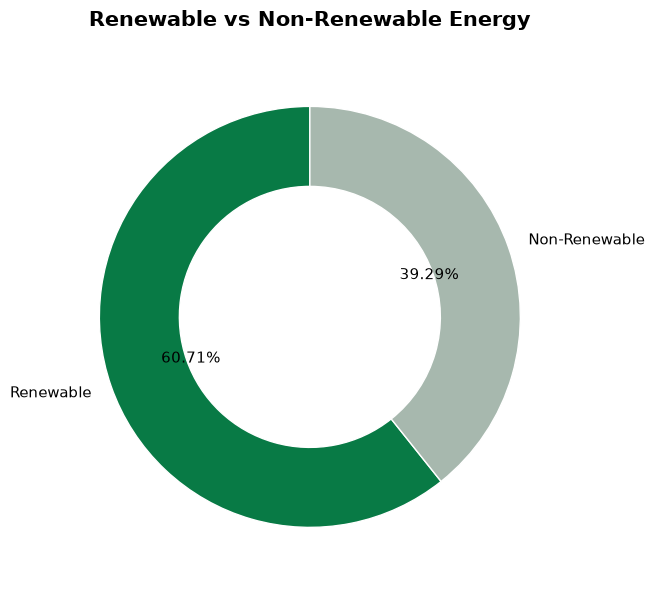

In [16]:
labels = ["Renewable", "Non-Renewable"]
values = [renewable_share, non_renewable_share]

colors = ["#087A45", "#A7B8AE"]

plt.figure(figsize=(8, 6))

plt.pie(
    values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90,
    colors=colors,
    wedgeprops={
        "width": 0.38,
        "edgecolor": "white"
    },
    textprops={"fontsize": 11}
)

plt.title(
    "Renewable vs Non-Renewable Energy",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.show()

## 6. Monthly Generation Trends

Aggregate generation by month and visualize the overall trend. For month-to-month comparisons, the analysis focuses on complete months from December 2025 through October 2026; the partial November periods are excluded from that comparison.

In [17]:
# Tarix sütunundan ay məlumatını götürək
df["month"] = df["Start date"].dt.to_period("M")

# Hər ay üzrə enerji istehsalını hesablayaq
monthly_generation = (
    df.groupby("month")[energy_columns]
    .sum()
    .sum(axis=1)
    .reset_index(name="total_generation_mwh")
)

monthly_generation["month"] = monthly_generation["month"].astype(str)

monthly_generation["total_generation_mwh"] = (
    monthly_generation["total_generation_mwh"] / 1_000_000
)

monthly_generation

,month,total_generation_mwh
0,2025-11,31.153766
1,2025-12,39.429885
2,2026-01,45.796867
3,2026-02,40.987463
4,2026-03,39.639978
5,2026-04,36.278894
6,2026-05,34.460824
7,2026-06,34.197199
8,2026-07,37.540032
9,2026-08,36.103149


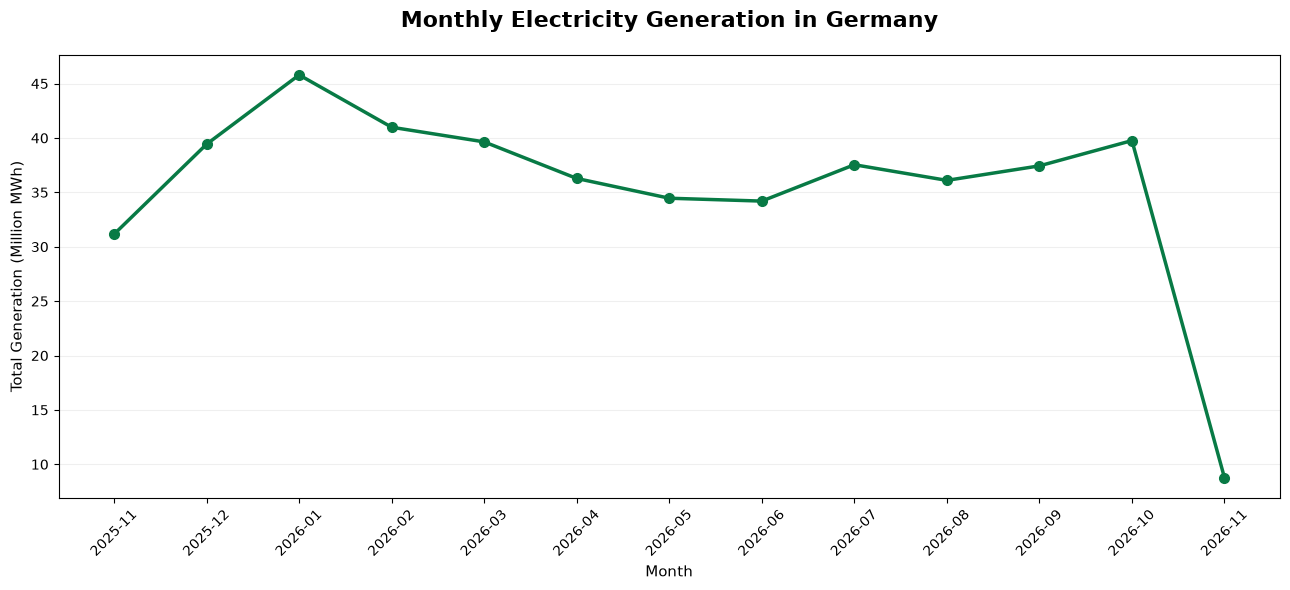

In [18]:
plt.figure(figsize=(13, 6))

plt.plot(
    monthly_generation["month"],
    monthly_generation["total_generation_mwh"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#087A45"
)

plt.title(
    "Monthly Electricity Generation in Germany",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=11)
plt.ylabel("Total Generation (Million MWh)", fontsize=11)

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

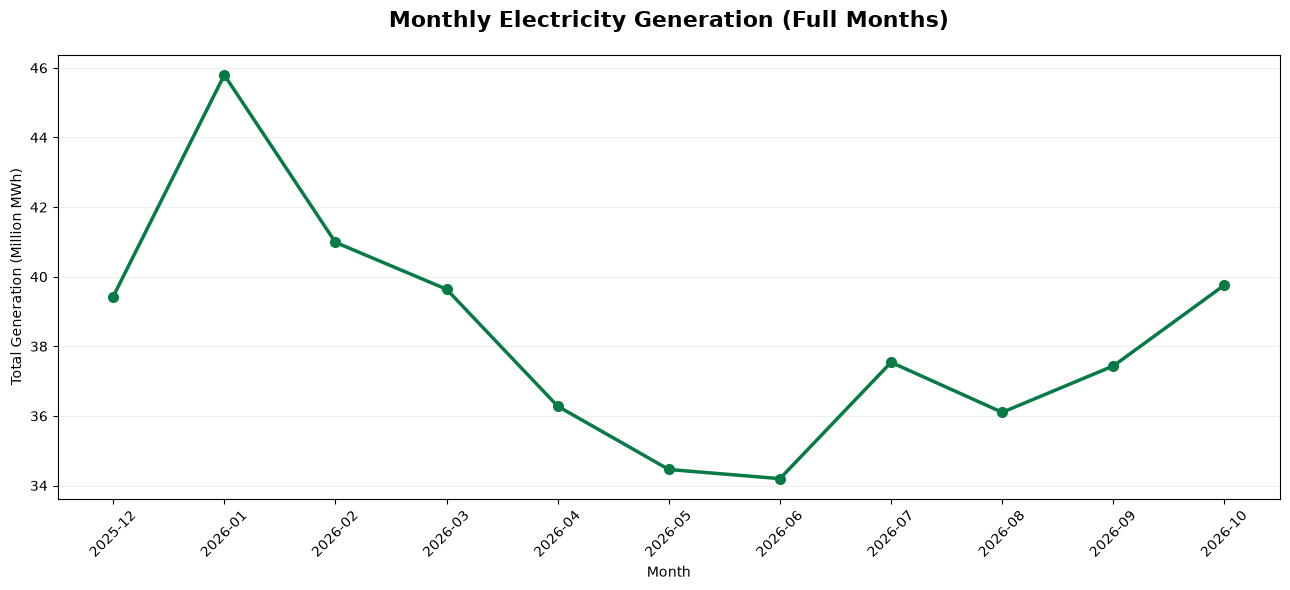

In [19]:
# Yalnız tam ayları seçirik
full_months = monthly_generation[
    (monthly_generation["month"] >= "2025-12") &
    (monthly_generation["month"] <= "2026-10")
].copy()

# Qrafik
plt.figure(figsize=(13, 6))

plt.plot(
    full_months["month"],
    full_months["total_generation_mwh"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#087A45"
)

plt.title(
    "Monthly Electricity Generation (Full Months)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month")
plt.ylabel("Total Generation (Million MWh)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [20]:
# Ən yüksək istehsal olan ay
max_month = full_months.loc[
    full_months["total_generation_mwh"].idxmax()
]

# Ən aşağı istehsal olan ay
min_month = full_months.loc[
    full_months["total_generation_mwh"].idxmin()
]

print("Highest Generation:")
print(max_month)

print("\nLowest Generation:")
print(min_month)

Highest Generation:
month                     2026-01
total_generation_mwh    45.796867
Name: 2, dtype: object

Lowest Generation:
month                     2026-06
total_generation_mwh    34.197199
Name: 7, dtype: object


## 7. Monthly Energy Mix and Heatmap

Compare monthly generation by source and use a heatmap to make differences between energy sources and months easier to identify.

In [21]:
# Enerji mənbələri üzrə aylıq istehsal
monthly_by_source = df_renewable.copy()

monthly_by_source["month"] = (
    df["Start date"].dt.to_period("M").astype(str)
)

monthly_by_source = (
    monthly_by_source
    .groupby("month")
    .sum()
)

# Yalnız 11 tam ayı götürək
monthly_by_source = monthly_by_source.loc["2025-12":"2026-10"]

# Milyon MWh formatına çevirək
monthly_by_source = (
    monthly_by_source / 1_000_000
).round(2)

monthly_by_source

,Biomass,Hydropower,Wind offshore,Wind onshore,Photovoltaics,Other renewable,Lignite,Hard coal,Fossil gas,Hydro pumped storage,Other conventional
month,,,,,,,,,,,
2025-12,3.19,1.02,3.43,12.47,1.51,0.09,5.44,2.60,7.52,0.72,1.43
2026-01,3.20,0.92,3.72,13.04,1.64,0.08,6.86,4.40,9.81,0.75,1.38
2026-02,2.86,1.00,3.69,11.14,2.54,0.07,6.44,3.32,8.04,0.61,1.28
2026-03,3.06,1.14,2.32,9.12,7.30,0.07,6.83,2.98,4.65,0.87,1.31
2026-04,2.96,1.07,1.83,7.87,10.05,0.07,4.22,2.23,3.79,0.91,1.28
2026-05,2.94,1.14,1.54,5.49,11.55,0.08,4.51,1.92,3.15,0.94,1.21
2026-06,2.56,1.28,1.50,6.37,11.64,0.06,4.33,1.51,2.90,0.93,1.10
2026-07,2.71,0.99,2.00,8.12,12.02,0.07,4.88,1.84,2.62,1.00,1.30
2026-08,2.84,1.00,1.82,7.54,10.93,0.07,4.61,2.21,2.90,0.89,1.29


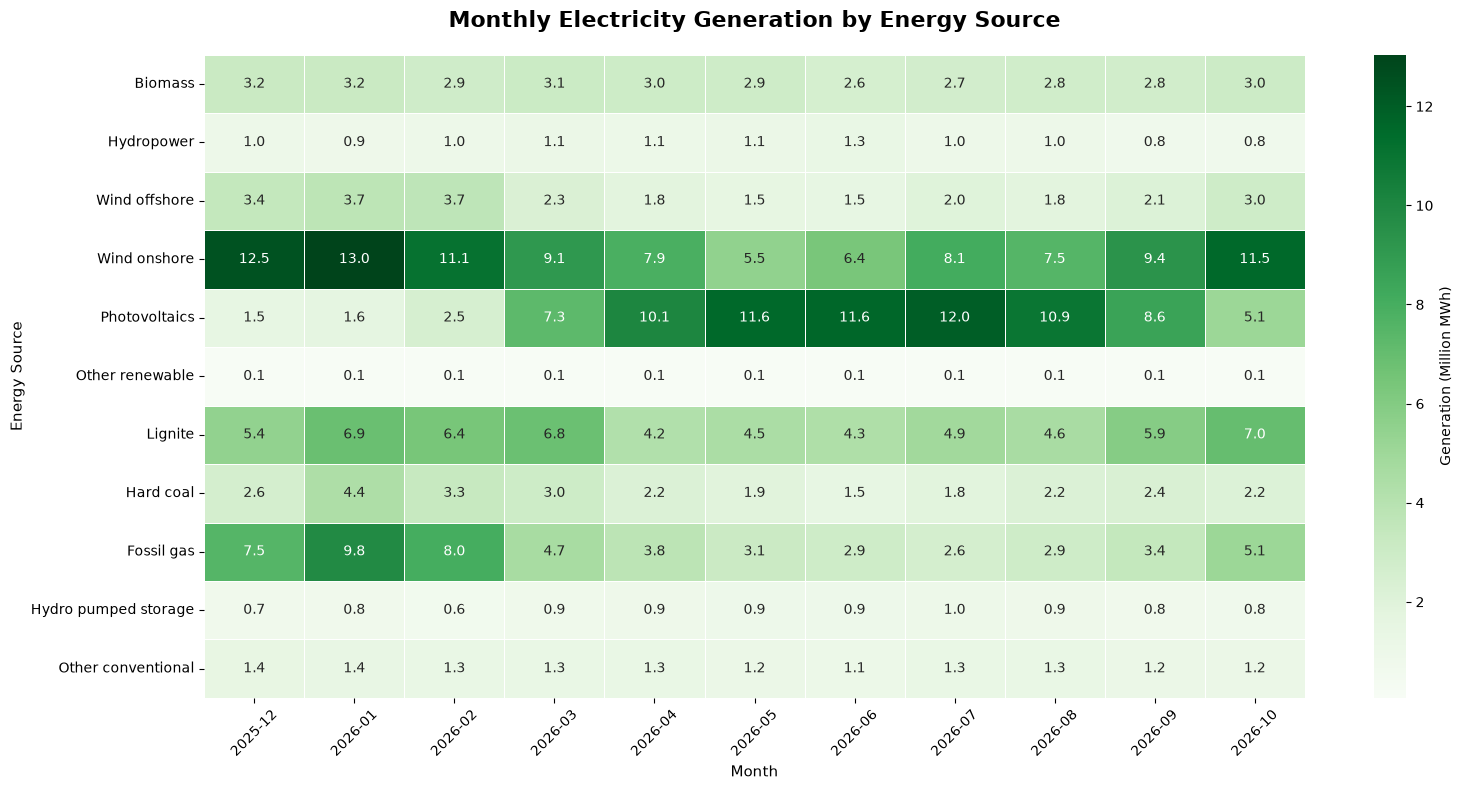

In [22]:
plt.figure(figsize=(16, 8))

sns.heatmap(
    monthly_by_source.T,
    annot=True,
    fmt=".1f",
    cmap="Greens",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Generation (Million MWh)"
    }
)

plt.title(
    "Monthly Electricity Generation by Energy Source",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=11)
plt.ylabel("Energy Source", fontsize=11)

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## 8. Peak Generation Analysis

Identify the month with the highest generation for each energy source and summarize the peak-month patterns.

In [23]:
# Hər enerji mənbəyinin maksimum istehsal etdiyi ay
max_month_by_source = monthly_by_source.idxmax()

# Həmin aylardakı istehsal həcmi
max_value_by_source = monthly_by_source.max()

source_peak_analysis = pd.DataFrame({
    "peak_month": max_month_by_source,
    "max_generation_mwh": max_value_by_source
}).sort_values(
    "max_generation_mwh",
    ascending=False
)

source_peak_analysis

,peak_month,max_generation_mwh
Wind onshore,2026-01,13.04
Photovoltaics,2026-07,12.02
Fossil gas,2026-01,9.81
Lignite,2026-10,7.00
Hard coal,2026-01,4.40
Wind offshore,2026-01,3.72
Biomass,2026-01,3.20
Other conventional,2025-12,1.43
Hydropower,2026-06,1.28
Hydro pumped storage,2026-07,1.00


## 9. Export the Cleaned Dataset

Export the prepared dataset as `germany-electricity-generation-clean.csv` for use in the Power BI dashboard. The export includes a `Year-Month` field formatted as `YYYY-MM`.

In [24]:
# Power BI üçün məlumatın surətini yaradaq
powerbi_data = df.copy()

# Ay sütununu uyğun formata çevirək
powerbi_data["month"] = (
    powerbi_data["Start date"].dt.strftime("%Y-%m")
)

# CSV faylını yaradaq
powerbi_data.to_csv(
    "germany-electricity-generation-clean.csv",
    index=False
)

print("Power BI dataset exported successfully!")
print("Rows:", len(powerbi_data))
print("Columns:", len(powerbi_data.columns))

Power BI dataset exported successfully!
Rows: 8781
Columns: 14


## 10. Key Notes and Interpretation

- The monthly comparison uses complete months only (December 2025–October 2026).
- Pumped storage is reported separately from the renewable and non-renewable primary-generation categories.
- Interpret totals carefully where an analysis step explicitly includes all generation columns, including pumped storage.
- The notebook is an exploratory analysis; conclusions should be read in the context of the dataset's coverage period and data-cleaning decisions.